
# Task 4: SMS Spam Detection with Machine Learning

## Objective
To build a Natural Language Processing (NLP) model
that classifies messages as Spam or Ham.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- TF-IDF Vectorization
- Multinomial Naive Bayes
- Logistic Regression
- Matplotlib
- WordCloud

## Dataset
UCI SMS Spam Collection Dataset


In [1]:

import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
import pandas as pd

data_path = "spam.csv"

df = pd.read_csv(
    data_path,
    encoding="latin-1"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [3]:
df = df[["v1", "v2"]].copy()

df.columns = ["label", "message"]

print(df["label"].value_counts())

display(df.head())

label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
# Check total messages
print("Total messages:", len(df))

# Check class counts
print("\nMessage counts:")
print(df["label"].value_counts())

# Calculate percentages
print("\nMessage percentages:")
print(
    (df["label"].value_counts(normalize=True) * 100).round(2)
)

Total messages: 5572

Message counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Message percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [5]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


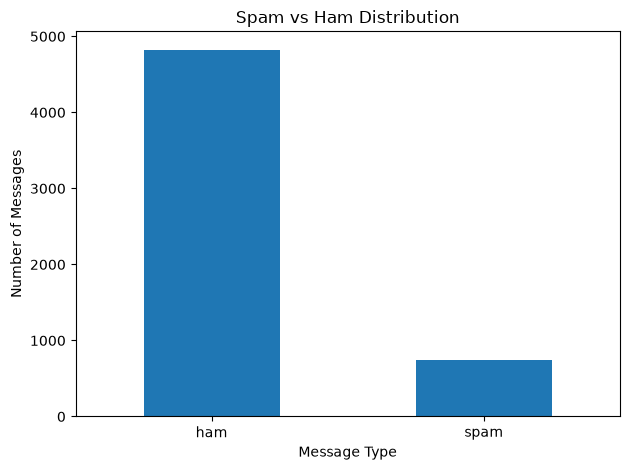

In [6]:
df["label"].value_counts().plot(
    kind="bar",
    title="Spam vs Ham Distribution",
    xlabel="Message Type",
    ylabel="Number of Messages"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [8]:
def clean_text(text):
    text = str(text).lower()

    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()

    stop_words = ENGLISH_STOP_WORDS - {"no", "not", "nor"}

    words = [word for word in words if word not in stop_words]

    return " ".join(words)


df["clean_message"] = df["message"].apply(clean_text)

print("Text preprocessing completed!")

display(df[["message", "clean_message", "label"]].head())

Text preprocessing completed!


,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis n great wor...,ham
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...,spam
3,U dun say so early hor... U c already then say...,u dun say early hor u c say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah don t think goes usf lives,ham



## TF-IDF Feature Extraction

TF-IDF stands for Term Frequency-Inverse Document Frequency.

TF measures how frequently a word appears in a message.

IDF measures how important a word is across all messages.

TF-IDF converts text into numerical values so that
machine learning algorithms can understand the text.

It gives more importance to informative words and
less importance to very common words.


In [9]:
X = df["clean_message"]

y = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("Input data:", X.shape)
print("Target data:", y.shape)

Input data: (5572,)
Target data: (5572,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 4457
Testing data: 1115


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    lowercase=False
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF completed!")
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

TF-IDF completed!
Training shape: (4457, 5000)
Testing shape: (1115, 5000)


In [12]:
from sklearn.naive_bayes import MultinomialNB

# Create model
nb_model = MultinomialNB()

# Train model
nb_model.fit(X_train_tfidf, y_train)

# Predict test data
nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes Model trained successfully!")

Naive Bayes Model trained successfully!


In [13]:
from sklearn.linear_model import LogisticRegression

# Create model
lr_model = LogisticRegression(max_iter=1000)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Predict test data
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression Model trained successfully!")

Logistic Regression Model trained successfully!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, predictions):

    print("\n", "=" * 40)
    print(name)
    print("=" * 40)

    print("Accuracy:",
          accuracy_score(y_true, predictions))

    print("Precision:",
          precision_score(y_true, predictions, pos_label=1))

    print("Recall:",
          recall_score(y_true, predictions, pos_label=1))

    print("F1 Score:",
          f1_score(y_true, predictions, pos_label=1))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        target_names=["Ham", "Spam"]
    ))


evaluate_model(
    "Multinomial Naive Bayes",
    y_test,
    nb_predictions
)

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions
)


Multinomial Naive Bayes
Accuracy: 0.9668161434977578
Precision: 0.9912280701754386
Recall: 0.7583892617449665
F1 Score: 0.8593155893536122

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       0.99      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115


Logistic Regression
Accuracy: 0.9650224215246637
Precision: 0.9910714285714286
Recall: 0.7449664429530202
F1 Score: 0.8505747126436781

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       0.99      0.74      0.85       149

    accuracy                           0.97      1115
   macro avg       0.98      0.87      0.92      1115
weighted avg       0.97      0.97      0.96      1115



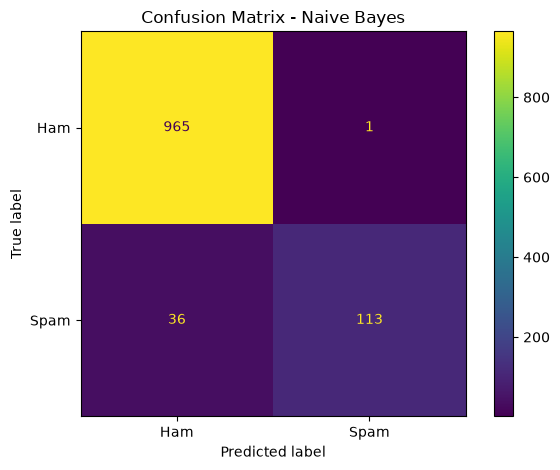

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_nb = confusion_matrix(
    y_test,
    nb_predictions,
    labels=[0, 1]
)

disp_nb = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Ham", "Spam"]
)

disp_nb.plot()
plt.title("Confusion Matrix - Naive Bayes")
plt.tight_layout()
plt.show()

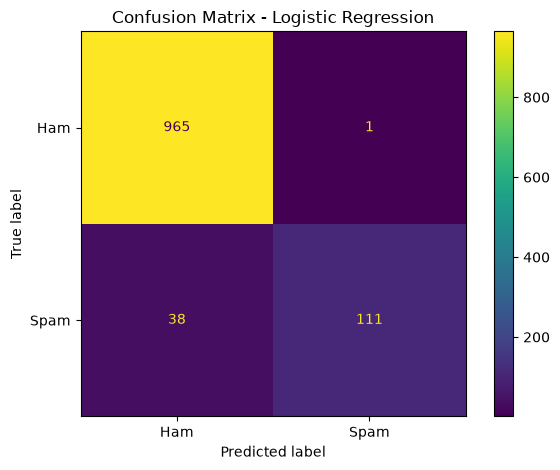

In [16]:
cm_lr = confusion_matrix(
    y_test,
    lr_predictions,
    labels=[0, 1]
)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Ham", "Spam"]
)

disp_lr.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


## Why Is Recall Important for Spam Detection?

Recall is important because it measures how many
actual spam messages are correctly identified.

Low recall means that many spam messages may reach
the user's inbox.

High recall helps detect more unwanted messages.
However, precision is also important because normal
messages should not be incorrectly marked as spam.

Therefore, both precision and recall are important
for a good spam detection system.


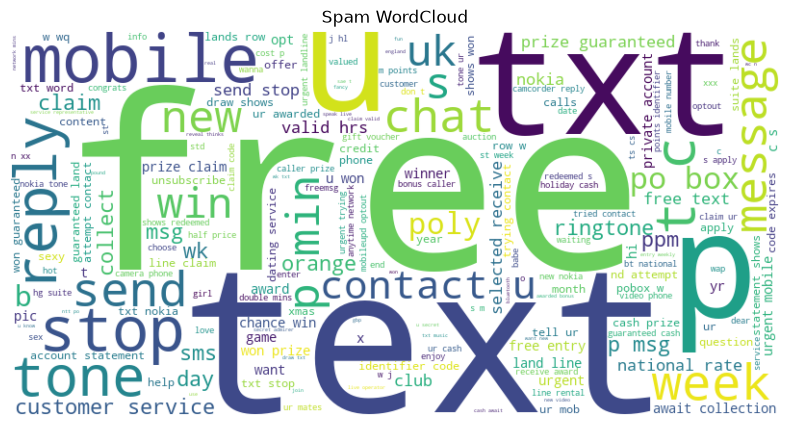

In [17]:
from wordcloud import WordCloud

spam_text = " ".join(
    df.loc[df["label"] == "spam", "clean_message"]
)

spam_cloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(spam_text)

plt.figure(figsize=(10, 5))
plt.imshow(spam_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Spam WordCloud")
plt.show()

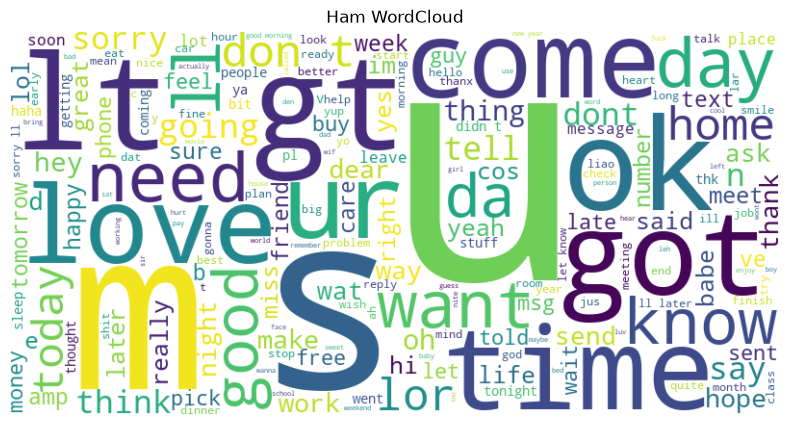

In [18]:
ham_text = " ".join(
    df.loc[df["label"] == "ham", "clean_message"]
)

ham_cloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(ham_text)

plt.figure(figsize=(10, 5))
plt.imshow(ham_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Ham WordCloud")
plt.show()

In [19]:
results = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression"
    ],

    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions)
    ],

    "Precision": [
        precision_score(y_test, nb_predictions, pos_label=1),
        precision_score(y_test, lr_predictions, pos_label=1)
    ],

    "Recall": [
        recall_score(y_test, nb_predictions, pos_label=1),
        recall_score(y_test, lr_predictions, pos_label=1)
    ],

    "F1 Score": [
        f1_score(y_test, nb_predictions, pos_label=1),
        f1_score(y_test, lr_predictions, pos_label=1)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.9668,0.9912,0.7584,0.8593
1,Logistic Regression,0.9650,0.9911,0.7450,0.8506



# Conclusion

In this project, an NLP-based Spam Detection System
was developed using Machine Learning.

The SMS Spam Collection dataset was used for training
and testing.

Text preprocessing and TF-IDF vectorization were
performed to prepare the messages.

Two classification algorithms were implemented:
1. Multinomial Naive Bayes
2. Logistic Regression

Both models were evaluated using accuracy, precision,
recall, F1-score and confusion matrix.

WordCloud visualizations were also created to
understand common words in spam and ham messages.

The project demonstrates how Machine Learning
can classify unwanted messages automatically.


In [1]:
import os

os.makedirs("results", exist_ok=True)

print("Results folder created successfully!")

Results folder created successfully!
